# Public health analysis — Outcomes, money, and risk factors

The question every policymaker actually asks: how do health outcomes relate to income, health spending, and behaviour? This notebook quantifies those relationships across countries — and spends exactly as much effort explaining why none of them is a causal estimate.

The caveat, up front rather than buried in the appendix: **everything here is cross-sectional description.** Income correlates with schooling, sanitation, health systems, nutrition and safety — all of which also correlate with health — and richer, longer-living societies also smoke more and eat more. The correlation matrix below shows smoking and obesity correlating *positively* with life expectancy across countries, and nobody believes cigarettes are good for you. That is confounding on full display, and it is why nothing in this notebook is phrased as an effect. `docs/limitations.md` has the full discussion.

Reads `../data/processed/panel.csv` from [data_wrangling.ipynb](data_wrangling.ipynb).

In [1]:
# Setup block -- same as the other notebooks so each one runs on its own.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from adjustText import adjust_text

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D8DEE4", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.labelsize": 10.5, "axes.labelcolor": "#4A5560",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.titlecolor": "#1A2530",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

REGION_COLORS = {
    "Africa": "#EE7733",
    "Asia": "#0077BB",
    "Europe": "#009988",
    "North America": "#33BBEE",
    "South America": "#CC3311",
    "Oceania": "#EE3377",
}
NEUTRAL, NEUTRAL_LIGHT, GRID = "#4A5560", "#9AA7B2", "#E8EDF1"
SOURCE_NOTE = ("Source: Our World in Data (UN WPP 2024, UN IGME 2024, World Bank, "
               "WHO GHO, IHME GBD, Maddison Project). CC BY 4.0.")

def headline(ax, title, subtitle=None):
    ax.set_title(title, loc="left", pad=34 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.045, subtitle, transform=ax.transAxes,
                fontsize=10, color=NEUTRAL, va="bottom")

def clean_axis(ax, grid=True, axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid:
        ax.grid(axis=axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)

def save(fig, name, note=SOURCE_NOTE):
    if note:
        fig.text(0.006, 0.008, note, fontsize=7.5, color=NEUTRAL_LIGHT, va="bottom")
        try:
            fig.get_layout_engine().set(rect=(0, 0.042, 1, 0.958))
        except Exception:
            pass
    path = f"../figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor="white")
    plt.show()
    print("saved", path)

def latest_snapshot(df, value, window=5):
    """Each country's most recent value within `window` years of the
    indicator's own latest year (they publish on different schedules)."""
    el = df.dropna(subset=[value])
    anchor = int(el["year"].max())
    el = el[el["year"].between(anchor - window + 1, anchor)]
    snap = (el.sort_values("year")
              .groupby("country", as_index=False)
              .tail(1)
              .rename(columns={"year": "ref_year", value: "value"}))
    cols = ["country", "iso3", "region", "ref_year", "value"]
    if "population" in snap.columns and value != "population":
        cols.append("population")
    return snap[cols]

def snapshot_multi(df, keys, window=5, min_pop_k=0):
    """One row per country, each indicator at its own latest vintage.
    min_pop_k drops microstates -- their volatile statistics dominate the
    corners of every cross-country scatter."""
    base = df[["country", "iso3", "region"]].drop_duplicates()
    for key in keys:
        s = latest_snapshot(df, key, window=window)[["country", "value", "ref_year"]]
        base = base.merge(s.rename(columns={"value": key, "ref_year": f"{key}_year"}),
                          on="country", how="left")
    if min_pop_k and "population" not in keys:
        pop = latest_snapshot(df, "population", window=window)[["country", "value"]]
        base = base.merge(pop.rename(columns={"value": "population"}),
                          on="country", how="left")
    if min_pop_k:
        base = base[base["population"].fillna(0) >= min_pop_k * 1000]
    return base.reset_index(drop=True)

def line_end_labels(ax, entries, dx_px=9, min_gap_px=15):
    """Right-edge direct labels with collision avoidance (see global_trends.ipynb)."""
    fig = ax.figure
    fig.canvas.draw()
    pts = [ax.transData.transform((e["x"], e["y"])) for e in entries]
    to_frac = ax.transAxes.inverted()
    order = sorted(range(len(entries)), key=lambda i: pts[i][1])
    ys = [pts[i][1] for i in order]
    for k in range(1, len(ys)):
        if ys[k] - ys[k - 1] < min_gap_px:
            ys[k] = ys[k - 1] + min_gap_px
    for k, idx in enumerate(order):
        e = entries[idx]
        fx, fy = to_frac.transform((pts[idx][0] + dx_px, ys[k]))
        ax.annotate(e["text"], xy=(e["x"], e["y"]), xycoords="data",
                    xytext=(fx, fy), textcoords="axes fraction",
                    fontsize=e.get("fontsize", 9.3),
                    fontweight=e.get("weight", "normal"),
                    color=e["color"], va="center")

def fit_semilog(x, y):
    """OLS of y on log10(x), reported in per-doubling units -- 'years per
    doubling of GDP' is something a person can hold in their head; a log-unit
    slope is not."""
    d = pd.concat([x.rename("x"), y.rename("y")], axis=1).dropna()
    d = d[d["x"] > 0]
    if len(d) < 10:
        return {}
    slope, intercept, r, p_value, stderr = stats.linregress(np.log10(d["x"]), d["y"])
    return {"slope_per_log10": float(slope),
            "slope_per_doubling": float(slope * np.log10(2)),
            "intercept": float(intercept), "r_squared": float(r**2),
            "p_value": float(p_value), "stderr": float(stderr), "n": int(len(d))}

def scatter_with_fit(ax, data, x, y, xlabel, ylabel):
    """Region-coloured bubbles (area ~ population) plus a dashed semilog fit."""
    for region, colour in REGION_COLORS.items():
        chunk = data[data["region"] == region]
        if chunk.empty:
            continue
        sizes = np.sqrt(chunk["population"].fillna(1e6)) / 18.0
        ax.scatter(chunk[x], chunk[y], s=sizes, color=colour, alpha=0.62,
                   edgecolors="white", linewidths=0.5, label=region, zorder=3)
    fit = fit_semilog(data[x], data[y])
    xs = np.array([data[x].min(), data[x].max()])
    ax.plot(xs, fit["intercept"] + fit["slope_per_log10"] * np.log10(xs),
            color="#6B7A88", linewidth=1.6, linestyle="--", zorder=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xscale("log")
    clean_axis(ax, grid=True, axis="both")
    return fit

def label_spots(ax, data, x, y, countries, force_text=(0.6, 0.9), dx=0.0, dy=0.0):
    """Country labels with automatic collision avoidance. The points are passed
    in too, so labels get pushed away from bubbles, not just from each other
    (a label inside a large bubble is unreadable even when it 'overlaps'
    nothing). dx/dy nudge the starting position -- useful for stepping out of
    the way of drawn lines, which adjust_text doesn't know about."""
    texts = []
    for country in countries:
        row = data[data["country"] == country]
        if row.empty or pd.isna(row[x].iloc[0]) or pd.isna(row[y].iloc[0]):
            continue
        texts.append(ax.text(row[x].iloc[0] * (1 + dx), row[y].iloc[0] + dy, country,
                             fontsize=8.8, color="#2E3A44"))
    if texts:
        pts = data[[x, y]].dropna()
        adjust_text(texts, ax=ax, x=list(pts[x]), y=list(pts[y]),
                    arrowprops=dict(arrowstyle="-", color=NEUTRAL_LIGHT, lw=0.7),
                    force_text=force_text, force_static=(0.35, 0.55),
                    expand=(1.15, 1.3))

def region_legend(ax, loc="upper left"):
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc=loc, ncol=2, fontsize=9,
              handletextpad=0.25, columnspacing=0.8, borderaxespad=0.4)

panel = pd.read_csv("../data/processed/panel.csv")
print(f"{panel.country.nunique()} countries · {len(panel):,} rows")

248 countries · 18,273 rows


## 1. Income

The relationship between GDP per capita and life expectancy is one of the most robust stylised facts in development economics — the *Preston curve*. It is also strongly convex: the same doubling of income buys far less health at the top of the income range than at the bottom. Hence the log x-axis and a fit of life expectancy on log GDP, reported **per doubling**.

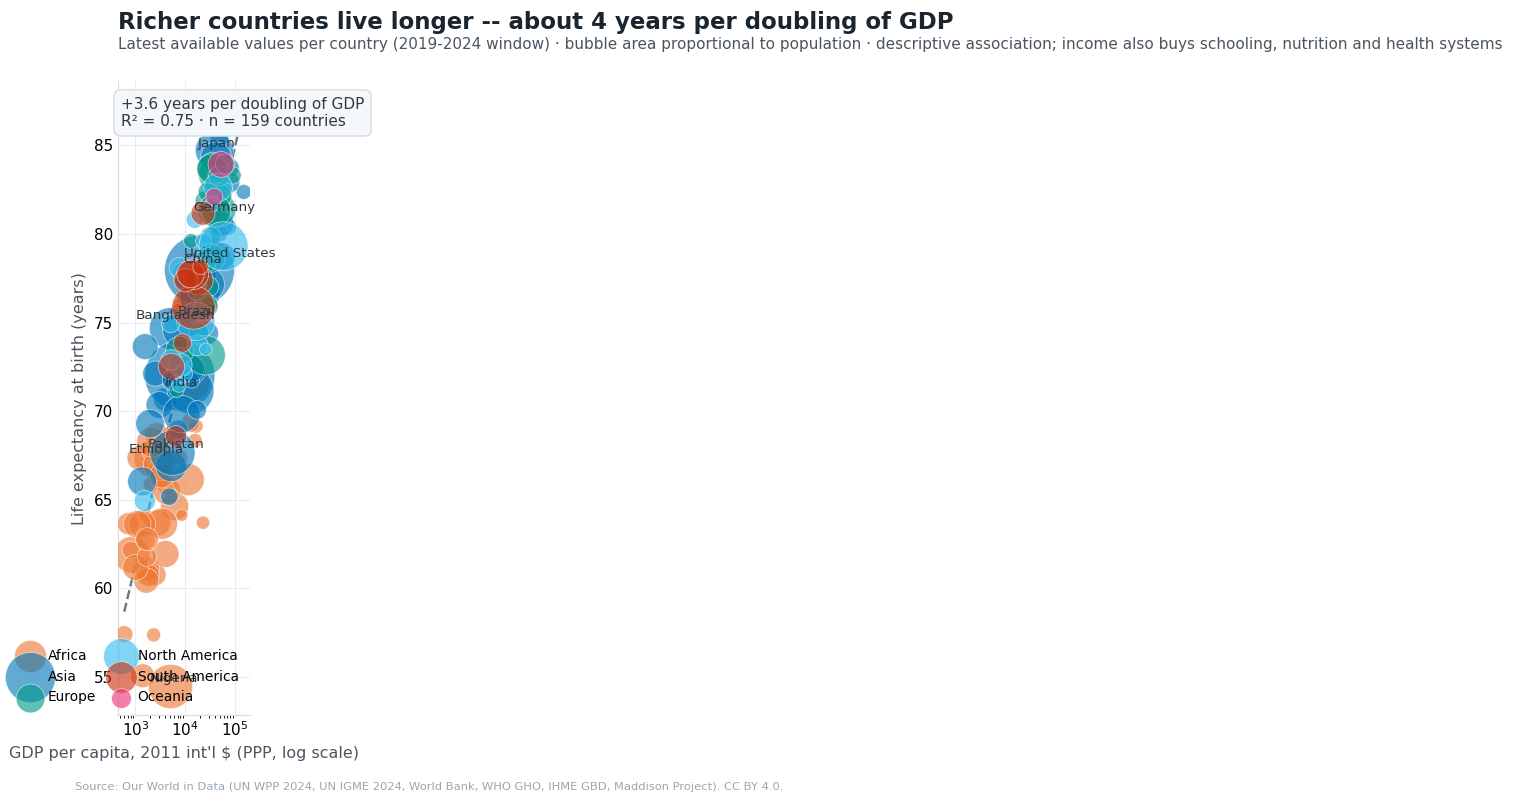

saved ../figures/gdp_vs_life_expectancy.png
slope per doubling: 3.56 yrs · R² 0.75 · n 159


In [2]:
snap = snapshot_multi(panel, ["life_expectancy", "gdp_pc", "population"],
                      window=5, min_pop_k=500)

fig, ax = plt.subplots(figsize=(10.8, 7.2), constrained_layout=True)
fit = scatter_with_fit(ax, snap, "gdp_pc", "life_expectancy",
                       "GDP per capita, 2011 int'l $ (PPP, log scale)",
                       "Life expectancy at birth (years)")
label_spots(ax, snap, "gdp_pc", "life_expectancy",
            ["United States", "Japan", "China", "India", "Nigeria", "Ethiopia",
             "Bangladesh", "Germany", "Brazil", "Pakistan"])
region_legend(ax, loc="lower right")

box = dict(boxstyle="round,pad=0.45", facecolor="#F5F8FA", edgecolor="#D8DEE4")
ax.annotate(f"+{fit['slope_per_doubling']:.1f} years per doubling of GDP\n"
            f"R² = {fit['r_squared']:.2f} · n = {fit['n']} countries",
            xy=(0.02, 0.975), xycoords="axes fraction", va="top",
            fontsize=10, color="#2E3A44", bbox=box)
headline(ax, f"Richer countries live longer -- about {fit['slope_per_doubling']:.0f} years per doubling of GDP",
         "Latest available values per country (2019-2024 window) · bubble area proportional to population · "
         "descriptive association; income also buys schooling, nutrition and health systems")
save(fig, "gdp_vs_life_expectancy")
print(f"slope per doubling: {fit['slope_per_doubling']:.2f} yrs · R² {fit['r_squared']:.2f} · n {fit['n']}")

- **About +3.6 years per doubling of GDP per capita** (R² ≈ 0.75, n = 159 countries above 500k) — one of the most-cited relationships in development economics, reproduced here from raw data in one scatter.
- The *curvature* is the policy-relevant part: $1,000 → $2,000 per person travels with far more life expectancy than $30,000 → $60,000. Diminishing returns to income — which is another way of saying the health returns to the poorest countries' growth are enormous.
- What this does **not** say: that raising GDP by X adds Y years to a country. The association runs partly the other way too (healthier populations work more and earn more — the health-to-wealth channel is well documented), and income stands in for everything else money buys. This number describes how the world *looks*, not what any policy would do.

## 2. Health spending

If income is the background condition, spending is the thing a health ministry actually controls. Same construction, health expenditure per capita (PPP) on the x-axis — and this time the interesting countries are the ones *off* the line, so the residuals get labelled directly.

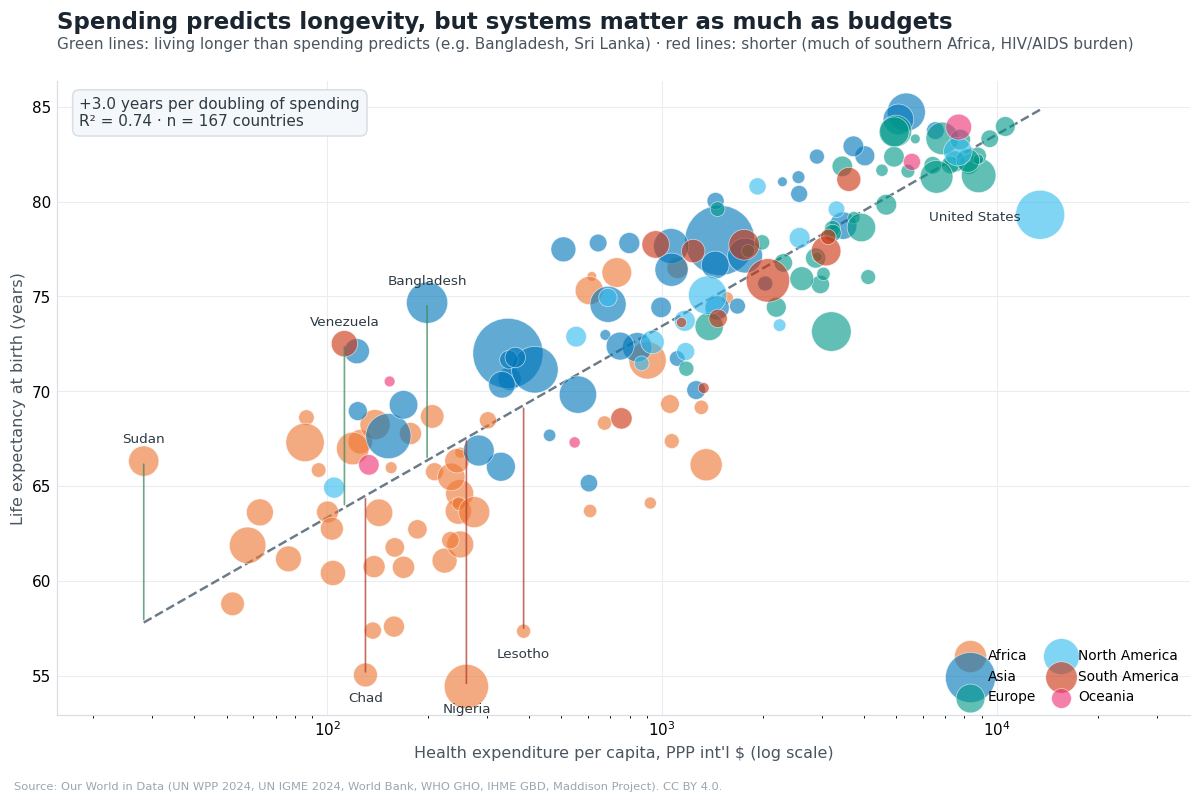

saved ../figures/spending_vs_life_expectancy.png
slope per doubling: 3.04 yrs · R² 0.74 · n 167


In [3]:
snap = (snapshot_multi(panel, ["life_expectancy", "health_spending_pc", "population"],
                       window=5, min_pop_k=500)
        .dropna(subset=["health_spending_pc", "life_expectancy"]))

fig, ax = plt.subplots(figsize=(10.8, 7.2), constrained_layout=True)
fit = scatter_with_fit(ax, snap, "health_spending_pc", "life_expectancy",
                       "Health expenditure per capita, PPP int'l $ (log scale)",
                       "Life expectancy at birth (years)")
# headroom on the right: the biggest spender (United States) sits at the axis
# edge and its label needs somewhere to go
ax.set_xlim(snap["health_spending_pc"].min() * 0.55,
            snap["health_spending_pc"].max() * 2.8)

# who lives longer / shorter than their spending predicts?
snap = snap.assign(
    predicted=fit["intercept"] + fit["slope_per_log10"] * np.log10(snap["health_spending_pc"]))
snap["residual"] = snap["life_expectancy"] - snap["predicted"]
over = snap.nlargest(3, "residual")
under = snap.nsmallest(3, "residual")
big_spender = snap.nlargest(1, "health_spending_pc")
labelled = pd.concat([over, under, big_spender]).drop_duplicates("country")
# hand-placed labels: above the point for over-performers (their residual
# arrow hangs *below* the point), below for under-performers (arrow above),
# and to the left for the US at the right edge. adjustText kept drifting
# them back onto the arrows.
for country in over["country"]:
    row = snap[snap["country"] == country].iloc[0]
    ax.annotate(country, (row["health_spending_pc"], row["life_expectancy"]),
                xytext=(0, 10), textcoords="offset points", ha="center",
                va="bottom", fontsize=8.8, color="#2E3A44")
for country in under["country"]:
    row = snap[snap["country"] == country].iloc[0]
    ax.annotate(country, (row["health_spending_pc"], row["life_expectancy"]),
                xytext=(0, -11), textcoords="offset points", ha="center",
                va="top", fontsize=8.8, color="#2E3A44")
row = big_spender.iloc[0]
ax.annotate("United States", (row["health_spending_pc"], row["life_expectancy"]),
            xytext=(-13, -2), textcoords="offset points", ha="right",
            va="center", fontsize=8.8, color="#2E3A44")
region_legend(ax, loc="lower right")

for _, row in over.iterrows():
    ax.annotate("", xy=(row["health_spending_pc"], row["life_expectancy"]),
                xytext=(row["health_spending_pc"], row["predicted"]),
                arrowprops=dict(arrowstyle="-", color="#3D8B5F", lw=1.1, alpha=0.75))
for _, row in under.iterrows():
    ax.annotate("", xy=(row["health_spending_pc"], row["predicted"]),
                xytext=(row["health_spending_pc"], row["life_expectancy"]),
                arrowprops=dict(arrowstyle="-", color="#B03A2E", lw=1.1, alpha=0.75))

box = dict(boxstyle="round,pad=0.45", facecolor="#F5F8FA", edgecolor="#D8DEE4")
ax.annotate(f"+{fit['slope_per_doubling']:.1f} years per doubling of spending\n"
            f"R² = {fit['r_squared']:.2f} · n = {fit['n']} countries",
            xy=(0.02, 0.975), xycoords="axes fraction", va="top",
            fontsize=10, color="#2E3A44", bbox=box)
headline(ax, "Spending predicts longevity, but systems matter as much as budgets",
         "Green lines: living longer than spending predicts (e.g. Bangladesh, Sri Lanka) · "
         "red lines: shorter (much of southern Africa, HIV/AIDS burden)")
save(fig, "spending_vs_life_expectancy")
print(f"slope per doubling: {fit['slope_per_doubling']:.2f} yrs · R² {fit['r_squared']:.2f} · n {fit['n']}")

In [4]:
# the residuals the arrows point at
cols = ["country", "region", "health_spending_pc", "life_expectancy", "predicted", "residual"]
print("living longer than spending predicts:")
display(over[cols].round(1))
print("living shorter than spending predicts:")
display(under[cols].round(1))

living longer than spending predicts:


,country,region,health_spending_pc,life_expectancy,predicted,residual
169,Venezuela,South America,112.4,72.5,63.9,8.6
148,Sudan,Africa,28.3,66.3,57.8,8.5
10,Bangladesh,Asia,198.5,74.7,66.4,8.3


living shorter than spending predicts:


,country,region,health_spending_pc,life_expectancy,predicted,residual
114,Nigeria,Africa,260.1,54.5,67.6,-13.1
87,Lesotho,Africa,385.6,57.4,69.3,-11.9
27,Chad,Africa,129.9,55.1,64.5,-9.4


**+3.0 years per doubling of spending** (R² ≈ 0.74) — spending predicts longevity almost as well as GDP does. But the residuals are the policy-relevant part:

- **Above the line: Bangladesh, Sri Lanka, Venezuela** live 7–8.5 years longer than their spending predicts. Bangladesh and Sri Lanka are the classic "good health at low cost" cases — primary-care systems, community health worker programmes, early national immunization and ORT pushes. (Venezuela's position reflects an oil-era income that current spending data doesn't fully track — a vintage artifact as much as a system story.)
- **Below the line: Nigeria, Lesotho, Chad** live 9–13 years shorter than spending predicts. Southern Africa's below-trend position is largely the HIV/AIDS burden; a country fighting an epidemic spends more and dies younger.
- **The United States** — the largest spender per capita by far — sits visibly below the line, the standard observation in every cross-system comparison.

Careful with the obvious reading, though: a below-trend country is not necessarily "inefficient". It may have an epidemic, a conflict legacy, or a different epidemiological profile. The residuals generate hypotheses; they don't settle them.

## 3. The correlation matrix (the warning-label chart)

Eleven indicators, one Spearman matrix, latest value per country. Rank correlation because these relationships are monotone but strongly non-linear. Pairwise-complete samples: every pair uses all countries where both indicators exist, which is why the n's differ — the sample-size matrix is saved alongside the correlations so nobody has to wonder.

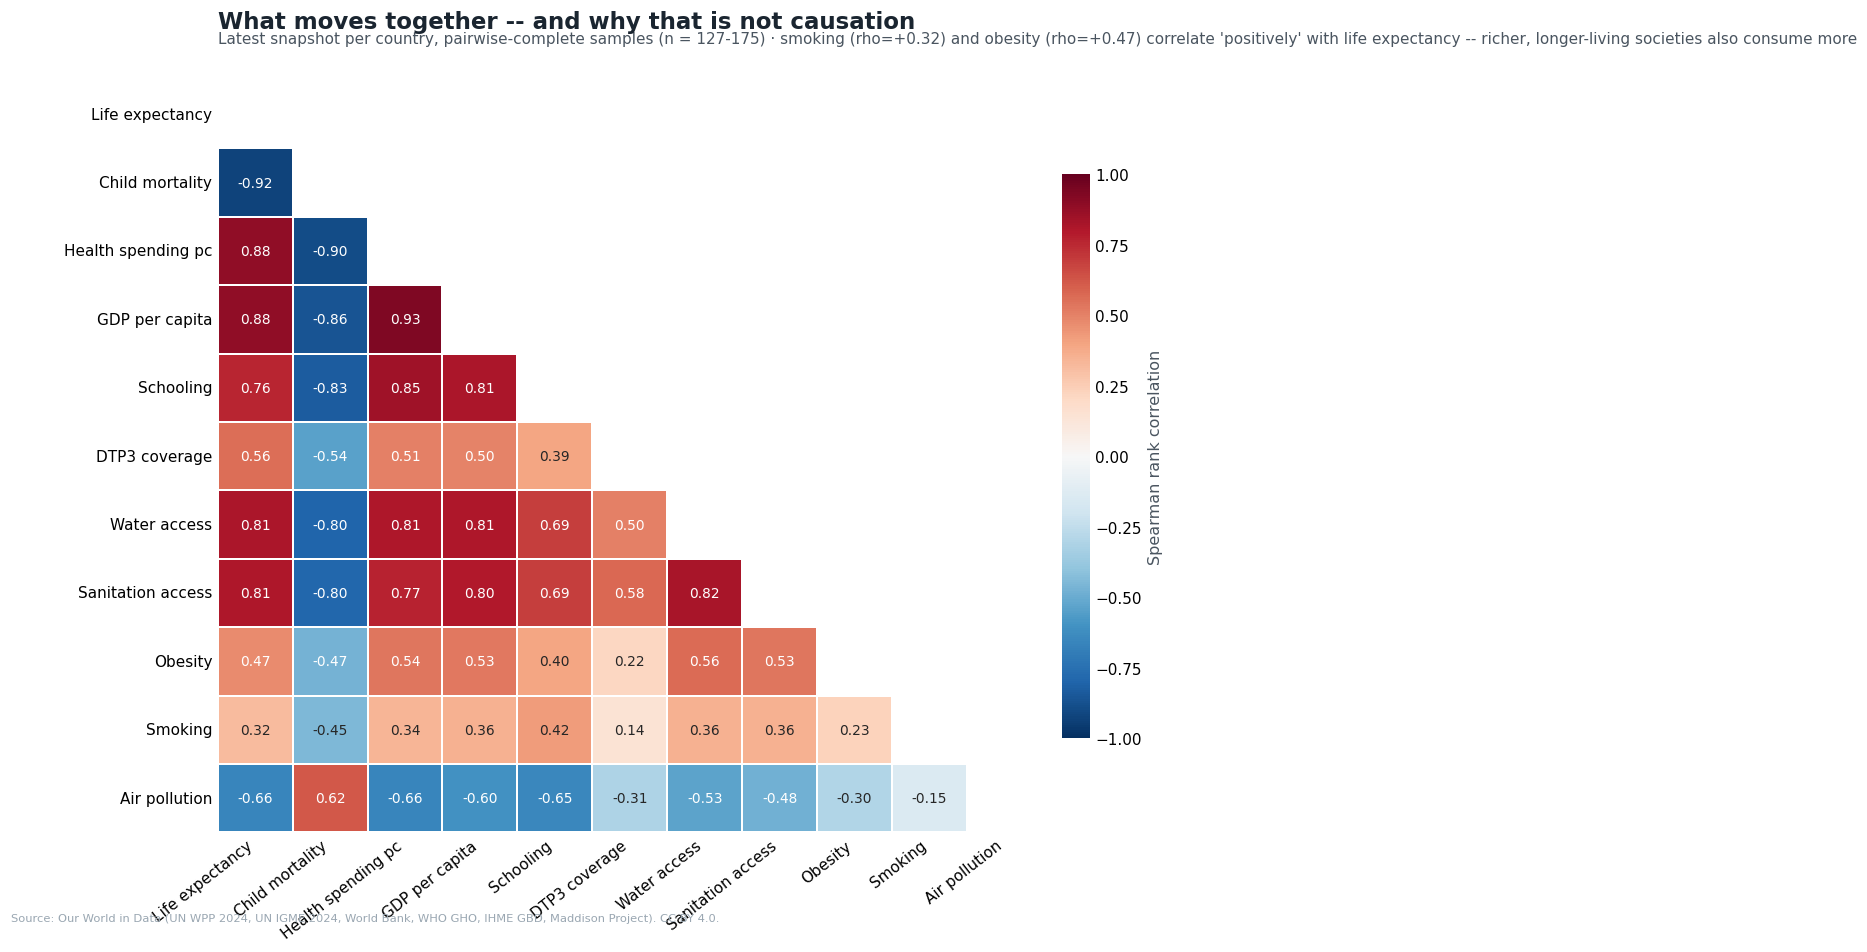

saved ../figures/correlation_heatmap.png


In [5]:
CORR_KEYS = ["life_expectancy", "child_mortality", "health_spending_pc", "gdp_pc",
             "schooling", "dtp3", "water_access", "sanitation_access",
             "obesity", "smoking", "air_pollution_deaths"]
SHORT = {"life_expectancy": "Life expectancy", "child_mortality": "Child mortality",
         "health_spending_pc": "Health spending pc", "gdp_pc": "GDP per capita",
         "schooling": "Schooling", "dtp3": "DTP3 coverage",
         "water_access": "Water access", "sanitation_access": "Sanitation access",
         "obesity": "Obesity", "smoking": "Smoking", "air_pollution_deaths": "Air pollution"}

snap_all = snapshot_multi(panel, CORR_KEYS + ["population"], window=5, min_pop_k=500)
corr = snap_all[CORR_KEYS].corr(method="spearman")
n_matrix = snap_all[CORR_KEYS].notna().astype(int).T.dot(snap_all[CORR_KEYS].notna().astype(int))
corr.round(3).to_csv("../data/processed/spearman_correlations.csv")
n_matrix.to_csv("../data/processed/spearman_sample_sizes.csv")

fig, ax = plt.subplots(figsize=(12.2, 9.0))   # manual layout -- constrained_layout
                                                 # chokes on the heatmap colorbar here
labels = [SHORT[k] for k in CORR_KEYS]
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 9},
            linewidths=1.1, linecolor="white",
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"shrink": 0.75, "pad": 0.02, "label": "Spearman rank correlation"})
ax.tick_params(axis="x", rotation=38)
for tick in ax.get_xticklabels():
    tick.set_ha("right")

smoking_r = corr.loc["smoking", "life_expectancy"]
obesity_r = corr.loc["obesity", "life_expectancy"]
fig.subplots_adjust(left=0.16, right=0.90, top=0.86, bottom=0.10)
headline(ax, "What moves together -- and why that is not causation",
         f"Latest snapshot per country, pairwise-complete samples (n = {int(n_matrix.values[n_matrix.values > 0].min())}-"
         f"{int(n_matrix.values.max())}) · smoking (rho={smoking_r:+.2f}) and obesity (rho={obesity_r:+.2f}) correlate "
         "'positively' with life expectancy -- richer, longer-living societies also consume more")
save(fig, "correlation_heatmap")

In [6]:
# the six semilog relationships in per-doubling units, saved for reference
pairs = [("gdp_pc", "life_expectancy"),
         ("health_spending_pc", "life_expectancy"),
         ("gdp_pc", "child_mortality"),
         ("water_access", "child_mortality"),
         ("sanitation_access", "child_mortality"),
         ("gdp_pc", "air_pollution_deaths")]
fits = pd.DataFrame([{"x": x, "y": y, **fit_semilog(snap_all[x], snap_all[y])}
                     for x, y in pairs]).round(3)
fits.to_csv("../data/processed/relationship_fits.csv", index=False)
fits[["x", "y", "slope_per_doubling", "r_squared", "n"]]

,x,y,slope_per_doubling,r_squared,n
0,gdp_pc,life_expectancy,3.555,0.748,159
1,health_spending_pc,life_expectancy,3.035,0.740,167
2,gdp_pc,child_mortality,-11.455,0.632,156
3,water_access,child_mortality,-128.869,0.582,164
4,sanitation_access,child_mortality,-41.317,0.595,163
5,gdp_pc,air_pollution_deaths,-9.565,0.301,155


Read the smoking and obesity rows first — the whole lesson of this notebook sits in those two cells of the matrix:

- **Smoking correlates about +0.3 with life expectancy; obesity about +0.5.** Both are risk factors. Both look "protective" across countries because income confounds everything: rich societies smoke more (historically) and eat more, and are longer-lived for other reasons.
- **GDP vs life expectancy: ρ ≈ +0.9**, the strongest relationship in the matrix — which is precisely why no arrow should ever be drawn between them.
- The matrix is displayed *because of* these embarrassments, not despite them. A reader should meet confounding in the data rather than in a footnote.

## 4. Two risk factors, opposite directions

The matrix's smoking and obesity rows make sense the moment you look at trends instead of levels: smoking (age-standardised) has collapsed in rich countries since 2000, while obesity (crude) has climbed nearly everywhere since 1980. Six large countries as tracers — and yes, the two series use different adjustment conventions, which is one more reason to compare directions, not levels (see `docs/limitations.md`).

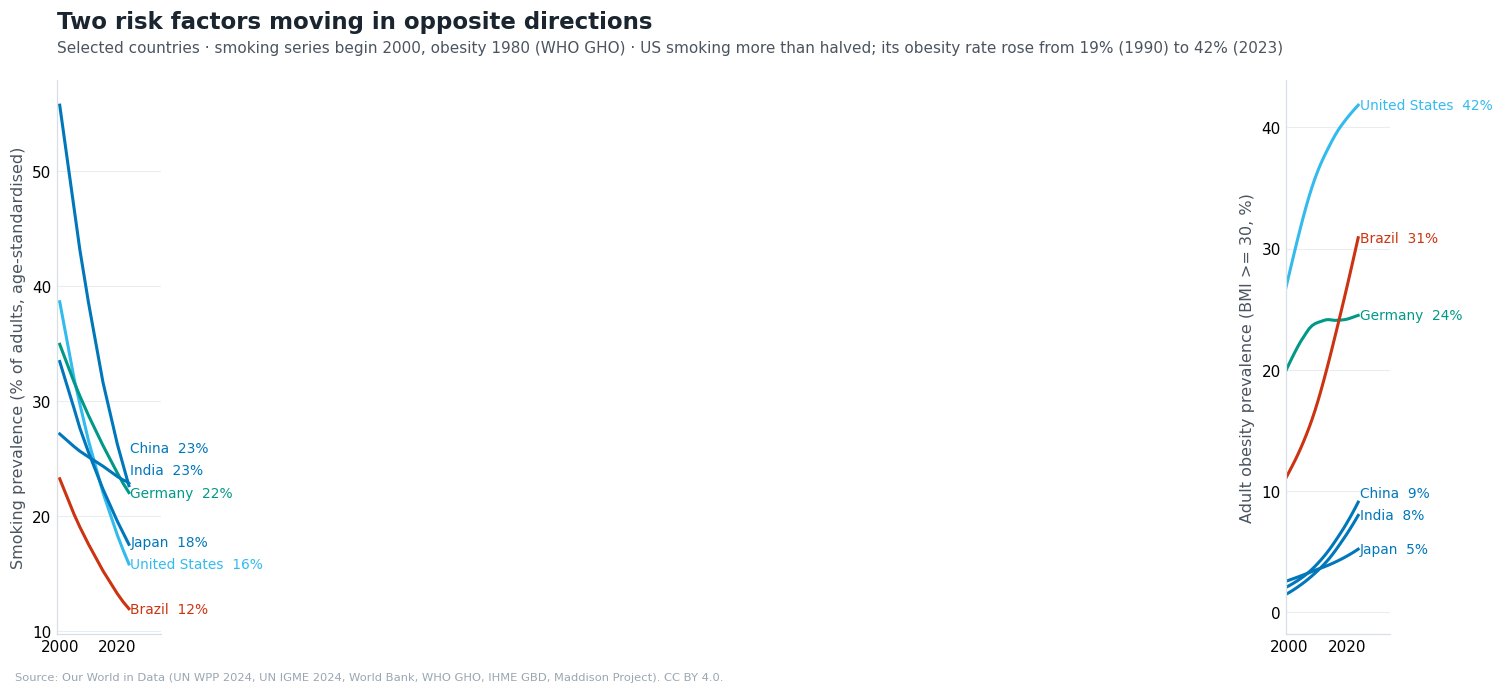

saved ../figures/risk_factor_trends.png


In [7]:
RISK_COUNTRIES = ["United States", "Germany", "Japan", "China", "Brazil", "India"]

fig, axes = plt.subplots(1, 2, figsize=(13.4, 6.2), constrained_layout=True)
panels = [
    ("smoking", "Smoking prevalence (% of adults, age-standardised)"),
    ("obesity", "Adult obesity prevalence (BMI >= 30, %)"),
]
for ax, (key, ylabel) in zip(axes, panels):
    d = panel[panel["country"].isin(RISK_COUNTRIES)].dropna(subset=[key])
    entries = []
    for country in RISK_COUNTRIES:
        s = d[d["country"] == country].sort_values("year")
        if s.empty:
            continue
        colour = REGION_COLORS.get(s["region"].iloc[0], NEUTRAL)
        ax.plot(s["year"], s[key], color=colour, linewidth=2.0)
        entries.append(dict(x=s["year"].iloc[-1], y=s[key].iloc[-1],
                            text=f"{country}  {s[key].iloc[-1]:.0f}%",
                            color=colour, fontsize=9))
    ax.set_ylabel(ylabel)
    ax.set_xlim(1999, 2035)
    clean_axis(ax)
    line_end_labels(ax, entries, dx_px=10, min_gap_px=26)

headline(axes[0], "Two risk factors moving in opposite directions",
         "Selected countries · smoking series begin 2000, obesity 1980 (WHO GHO) · "
         "US smoking more than halved; its obesity rate rose from 19% (1990) to 42% (2023)")
save(fig, "risk_factor_trends")

- **US smoking fell from 38.6% (2000) to ~16% (2024)** — more than halving in a generation, the single biggest voluntary risk-factor change in the panel. Germany and Japan follow the same slope.
- **US obesity rose from ~19% (1990) to ~42% (2023)** — the mirror image, and the reason the positive obesity–life-expectancy correlation in the matrix will eventually flip as today's middle-income countries age into their obesity epidemics.
- **Japan remains the outlier** everyone cites: obesity ~5%, longest lives on earth. China's smoking prevalence — still above one in five adults, overwhelmingly men — is the largest tobacco exposure on the planet by headcount.

## 5. Air pollution and income

The IHME GBD estimates are a single cross-section (2019) and a **modelled** attribution — exposure models plus concentration-response functions, not death certificates. They are useful precisely because they are comparable across countries; treat any single country's rank as indicative. Against log GDP:

poorest decile median: 79 per 100k · richest decile median: 14 per 100k
highest national rate: {'country': 'Tajikistan', 'air_pollution_deaths': 159.0}


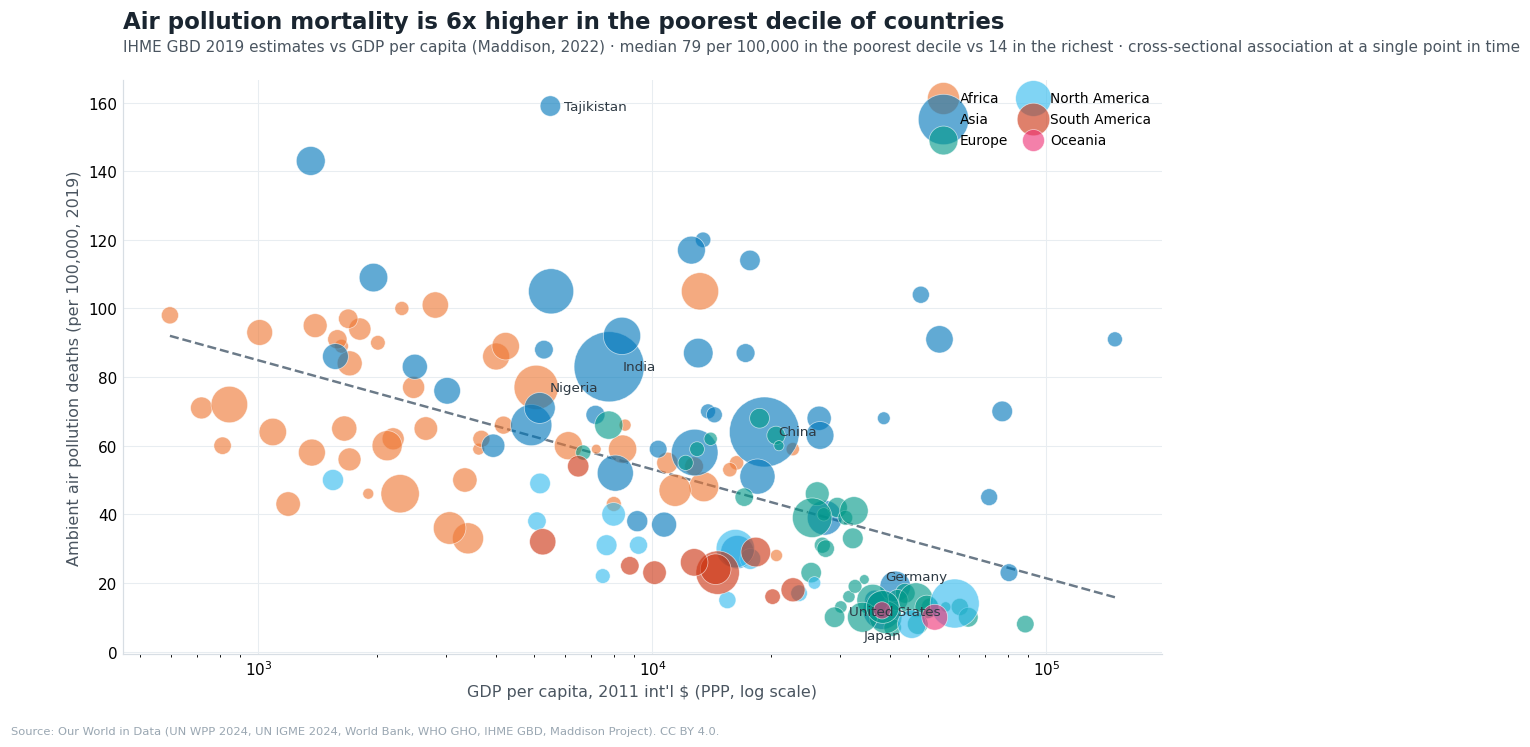

saved ../figures/air_pollution_vs_gdp.png


In [8]:
snap = (snapshot_multi(panel, ["air_pollution_deaths", "gdp_pc", "population"],
                       window=5, min_pop_k=500)
        .dropna(subset=["air_pollution_deaths", "gdp_pc"]))

fig, ax = plt.subplots(figsize=(10.8, 7.0))   # manual layout; the constrained
                                                # solver is flaky at this size
fit = scatter_with_fit(ax, snap, "gdp_pc", "air_pollution_deaths",
                       "GDP per capita, 2011 int'l $ (PPP, log scale)",
                       "Ambient air pollution deaths (per 100,000, 2019)")
# hand-placed offsets -- the bottom-right cluster (US, Japan, Germany) is
# too tight for the automatic label placement to settle on
AIR_OFFSETS = {
    "Tajikistan": (9, 0), "Nigeria": (9, 0), "India": (9, 0), "China": (9, 0),
    "United States": (-9, -1), "Japan": (0, -12), "Germany": (0, 11),
}
for country, (ox, oy) in AIR_OFFSETS.items():
    row = snap[snap["country"] == country]
    if row.empty:
        continue
    row = row.iloc[0]
    ax.annotate(country, (row["gdp_pc"], row["air_pollution_deaths"]),
                xytext=(ox, oy), textcoords="offset points",
                ha="left" if ox > 0 else ("right" if ox < 0 else "center"),
                va="bottom" if oy > 0 else ("top" if oy < 0 else "center"),
                fontsize=8.8, color="#2E3A44")
region_legend(ax, loc="upper right")
fig.subplots_adjust(left=0.10, right=0.975, top=0.86, bottom=0.115)

# decile medians keep the summary honest against outliers
deciles = snap.assign(gdp_decile=pd.qcut(snap["gdp_pc"], 10, labels=False))
poor = deciles[deciles["gdp_decile"] == 0]["air_pollution_deaths"].median()
rich = deciles[deciles["gdp_decile"] == 9]["air_pollution_deaths"].median()
print(f"poorest decile median: {poor:.0f} per 100k · richest decile median: {rich:.0f} per 100k")
print(f"highest national rate: {snap.nlargest(1, 'air_pollution_deaths')[['country', 'air_pollution_deaths']].iloc[0].to_dict()}")

headline(ax, f"Air pollution mortality is {poor / max(rich, .1):.0f}x higher in the poorest decile of countries",
         f"IHME GBD 2019 estimates vs GDP per capita (Maddison, 2022) · median {poor:.0f} per 100,000 "
         f"in the poorest decile vs {rich:.0f} in the richest · cross-sectional association at a single point in time")
save(fig, "air_pollution_vs_gdp")

- The median rate in the **poorest GDP decile (~79 per 100,000) is roughly six times the richest-decile median (~14)**; the highest national rate is Tajikistan's (~159). The scatter rises as income falls, all the way down the income ladder — the opposite gradient from life expectancy, and the sharpest one in the project.
- The cross-sectional *shape* (burden peaking in lower-middle-income countries) resembles the "environmental Kuznets curve" — but a cross-section is not a time series. It does **not** show that countries pollute first and clean up later; it shows where the burden sits *today*.
- These are modelled estimates with real uncertainty in low-data countries, and a single 2019 snapshot — the cleanest reading is "air pollution deaths concentrate where income is low", nothing more.

## What a causal version of this notebook would need

For anyone who wants the next step rather than the caveat: credible causal claims need designs that isolate variation — difference-in-differences around policy changes, instrumental variables, regression discontinuity, or randomised trials (J-PAL's and 3ie's repositories catalogue thousands in health). Good entry points: Angrist & Pischke, *Mostly Harmless Econometrics*, for identification strategies; Deaton, *The Analysis of Household Surveys*, for why cross-country regressions explain so little of what policymakers actually need to know.

## Recap

Money — income and spending — predicts health almost everywhere in this data, in per-doubling units a policymaker can use. The residuals from the spending line (Bangladesh above, Nigeria below, the US off to the right) are the most policy-interesting objects in the notebook, and precisely the ones this methodology cannot explain. The correlation matrix is left in the project as a deliberate exhibit of confounding.

Next: **[geographic_analysis.ipynb](geographic_analysis.ipynb)** — the same stories, drawn on the map.